# 04 Second encoder

In `02-Linear-models.ipynb` and `03-Attention-network.ipynb`, neither ridge nor the attention network got much out of
the FinBERT vectors, and the attention network did no better than ridge. By the decision rule in the plan
(`01-Research-and-Plan.md`, section 8), what is left to test is the vectors themselves. They come from
`ProsusAI/finbert` (Araci, 2019), which was tuned to label sentences as positive, negative or neutral, so its vectors
may mostly encode tone.

In this notebook, we read Item 7 again with a different encoder and rerun the same models on it, changing nothing
else:

| What | Before | Now | Why |
|---|---|---|---|
| Encoder | `ProsusAI/finbert`, tuned for sentiment | `yiyanghkust/finbert-pretrain` (Yang, Uy & Huang, 2020), pre-trained on 10-Ks, 10-Qs, earnings calls and analyst reports, not tuned for any task | Language closer to ours, and not narrowed to tone. FETILDA (Xia et al., 2022) found it the better of the two |
| Vector per chunk | The first token's vector (CLS) | Both the CLS vector and the average of the token vectors | A model never fine-tuned has not learnt to put a summary in its CLS token, so the average may be better |
| Section | Item 1 and Item 7 | Item 7 | The section that worked in notebooks 02 and 03 |
| Models | Within-year ridge, attention network | The same, unchanged (`ridge_sums.py`, `attention.py`) | So any difference is down to the vectors |

Reusing a pre-trained model to turn text into vectors, without changing its weights, is transfer learning, which the
brief lists. Fine-tuning the encoder is the step after this one, if these vectors carry signal.

**This runs on a Colab GPU, in two stages.** With `GO = False` (section 2), Run all only sets up and checks the inputs,
the tokenizer and the speed, and stops. After the checks have been looked at, set `GO = True` and Run all again:
it embeds Item 7 (about an hour on a T4, resumable) and trains the models (about half an hour), saving everything to
Google Drive.

## 1. Setup

On Colab, the first cell installs pandas 3 (for `data.pkl`), connects Google Drive and gets the repo. The Item 7
text comes from Oscar's shared folder (`sprint2-data/text`), linked into the places his `Oscar/extract_finbert.py`
reads from, so we use his rules for which text to read. Kogan et al.'s text, used for the 2% of reports where
EDGAR-CORPUS's Item 7 is nearly empty, is downloaded from their public site.

In [23]:
import importlib.metadata, importlib.util, os, shutil, subprocess, sys
from pathlib import Path

NOTEBOOK_DIR = "Alex"
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    # data.pkl was written with pandas 3 and Colab ships pandas 2, which cannot read it.
    if int(importlib.metadata.version("pandas").split(".")[0]) < 3:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pandas==3.0.6"], check=True)
        if "pandas" in sys.modules:
            print("pandas 3 installed but the old one was already loaded: restarting the runtime. Run all again.")
            os.kill(os.getpid(), 9)
    from google.colab import drive
    drive.mount("/content/drive")
    repo = Path("/content/dst-sprint2")
    if repo.exists():
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", "https://github.com/Oscar339/dst-sprint2.git", str(repo)], check=True)
    processed = repo / "data" / "processed"
    processed.mkdir(parents=True, exist_ok=True)
    if not (processed / "data.pkl").exists():
        shutil.copy(Path("/content/drive/MyDrive/sprint2-data/data.pkl"), processed / "data.pkl")
    os.chdir(repo / NOTEBOOK_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [24]:
import pickle, sys, time, platform, urllib.request
sys.path.insert(0, "."); sys.path.insert(0, "../Oscar")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import attention
import ridge_sums
import scoring

DEVICE = attention.DEVICE
print(f"Python {platform.python_version()} | torch {torch.__version__} | device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))

with open("../data/processed/data.pkl", "rb") as f:
    d = pickle.load(f)
df = scoring.frame(d)
x_all, yr_all = df["logvol_before"].to_numpy(), df["year"].to_numpy()
print(f"{len(df):,} reports, {df.year.min()}-{df.year.max()}")

DRIVE = Path("/content/drive/MyDrive/sprint2-data")
TEXT_DIR = DRIVE / "text"                      # Oscar's shared folder: edgar_matched/ and item7_source.csv
OUT_DIR = DRIVE / "second-encoder"             # everything this notebook makes; survives the session
EMB_DIR = OUT_DIR / "yang-item7"               # shards of chunk vectors, 250 reports each
RESULTS_FILE, RUNS_FILE = OUT_DIR / "alex-04-results.csv", OUT_DIR / "alex-04-runs.csv"
TIMING_FILE = OUT_DIR / "alex-04-embedding-timing.csv"

PROCESSED, KOGAN = Path("../data/processed"), Path("../data/raw/kogan")
if IN_COLAB:
    assert (TEXT_DIR / "item7_source.csv").exists() and (TEXT_DIR / "edgar_matched").exists(), \
        f"Oscar's text is not in {TEXT_DIR}: add the shared folder to My Drive as sprint2-data/text"
    shutil.copy(TEXT_DIR / "item7_source.csv", PROCESSED / "item7_source.csv")
    if not (PROCESSED / "edgar_matched").exists():
        (PROCESSED / "edgar_matched").symlink_to(TEXT_DIR / "edgar_matched")
    KOGAN.mkdir(parents=True, exist_ok=True)
    for yr in range(1996, 2007):
        target = KOGAN / f"{yr}.tok.tgz"
        if not target.exists():
            urllib.request.urlretrieve(f"https://www.cs.cmu.edu/~ark/10K/data/{target.name}", target)
    EMB_DIR.mkdir(parents=True, exist_ok=True)
    print("edgar_matched files:", sorted(p.name for p in (PROCESSED / "edgar_matched").iterdir()))
    print("Kogan text files:", len(list(KOGAN.glob("*.tok.tgz"))))

Python 3.13.16 | torch 2.14.1+cu130 | device cuda (Tesla T4)
27,142 reports, 1996-2006
edgar_matched files: ['1996.jsonl.gz', '1997.jsonl.gz', '1998.jsonl.gz', '1999.jsonl.gz', '2000.jsonl.gz', '2001.jsonl.gz', '2002.jsonl.gz', '2003.jsonl.gz', '2004.jsonl.gz', '2005.jsonl.gz', '2006.jsonl.gz', 'edgar_counts.json']
Kogan text files: 11


## 2. The encoder, and checks before running

Yang et al.'s model comes with its own vocabulary of 30,873 word pieces, chosen from financial text, but with no
tokenizer settings. The vocabulary is all lower case, so the tokenizer has to be told to lower-case the text, or
every capitalised word would become `[UNK]` (unknown). The checks below confirm this on real reports, comparing the
share of unknown tokens with the ProsusAI tokenizer we used before.

Each report's Item 7 is then cut into chunks of 510 word pieces, at most 64 per report, exactly as Oscar did
(`Oscar/extract_finbert.py`), and each chunk is passed through the model once. For each chunk we keep two 768-number
vectors: the CLS token's, and the average over the chunk's tokens. The weights are loaded in half precision (fp16),
as Oscar did after checking it changes the vectors very little.

The model is pinned to one revision, so a rerun reads exactly the same weights.

In [25]:
GO = True          # False: checks only. Set to True once the checks below look right, then Run all again.

from huggingface_hub import hf_hub_download
from tokenizers import BertWordPieceTokenizer
from transformers import AutoTokenizer, BertModel, PreTrainedTokenizerFast
from extract_finbert import CHUNK, MAX_CHUNKS, load_plan, load_texts   # Oscar's chunk size, cap and text rules

YANG, REVISION = "yiyanghkust/finbert-pretrain", "88ab954a39ea6d3ce2b62cff086dd5ad1172c664"
# Built from the vocabulary with the tokenizers library: transformers 5 ignores vocab_file= in BertTokenizerFast
# and silently gives a 5-word vocabulary, so every word would become [UNK].
tok = PreTrainedTokenizerFast(
    tokenizer_object=BertWordPieceTokenizer(hf_hub_download(YANG, "vocab.txt", revision=REVISION), lowercase=True),
    unk_token="[UNK]", sep_token="[SEP]", pad_token="[PAD]", cls_token="[CLS]", mask_token="[MASK]")
tok.model_max_length = 10 ** 9      # we cut into chunks ourselves; this only silences a length warning
encoder = BertModel.from_pretrained(YANG, revision=REVISION, dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
encoder = encoder.to(DEVICE).eval()
assert tok.vocab_size == 30_873, "the tokenizer did not load Yang's vocabulary"
print(f"vocabulary {tok.vocab_size:,} | special tokens CLS={tok.cls_token_id} SEP={tok.sep_token_id} PAD={tok.pad_token_id} UNK={tok.unk_token_id}")
print(f"encoder: {sum(p.numel() for p in encoder.parameters()) / 1e6:.0f}M parameters, {next(encoder.parameters()).dtype}")
print("tokens of 'Net Sales INCREASED due to the Merger':", tok.tokenize("Net Sales INCREASED due to the Merger"))

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: yiyanghkust/finbert-pretrain
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocabulary 30,873 | special tokens CLS=3 SEP=4 PAD=0 UNK=2
encoder: 110M parameters, torch.float16
tokens of 'Net Sales INCREASED due to the Merger': ['net', 'sales', 'increased', 'due', 'to', 'the', 'merger']


In [26]:
plan = load_plan()
assert set(plan["key"]) == set(df["key"]), "the reports to embed must be exactly the reports in data.pkl"
sample_rows = plan[plan["year"] == 2006].head(40)
sample = [t for _, t in load_texts(2006, sample_rows).values()]
prosus = AutoTokenizer.from_pretrained("ProsusAI/finbert")

def unk_share(tokenizer, texts):
    ids = [tokenizer(t, add_special_tokens=False)["input_ids"] for t in texts]
    return sum(i.count(tokenizer.unk_token_id) for i in ids) / sum(len(i) for i in ids), sum(len(i) for i in ids)

u_yang, n_yang = unk_share(tok, sample)
u_prosus, n_prosus = unk_share(prosus, sample)
print(f"40 Item 7 texts from 2006: unknown tokens - Yang {u_yang:.3%}, ProsusAI {u_prosus:.3%}; "
      f"word pieces - Yang {n_yang:,}, ProsusAI {n_prosus:,} ({n_yang / n_prosus - 1:+.0%})")
assert u_yang < 0.01, "too many unknown tokens: check the tokenizer is lower-casing"

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (6703 > 512). Running this sequence through the model will result in indexing errors


40 Item 7 texts from 2006: unknown tokens - Yang 0.008%, ProsusAI 0.000%; word pieces - Yang 421,787, ProsusAI 439,739 (-4%)


**Speed.** Embedding is the expensive step, and every chunk is independent of every other, so it is embarrassingly
parallel (lecture 09.1, slides 9 to 10): at 1000 times the data it splits across as many GPUs as are available, as the
map step of lecture 09.2. On one GPU the batch size decides how well the GPU's many cores are used (lecture 09.1,
slide 5). We time a fixed set of chunks at several batch sizes, and use the fastest to estimate the full run.

In [27]:
def chunk_ids(texts):
    out, kept, true = [], [], []
    for t in texts:
        ids = tok(t, add_special_tokens=False)["input_ids"]
        pieces = [ids[i:i + CHUNK] for i in range(0, len(ids), CHUNK)]
        true.append(len(pieces)); pieces = pieces[:MAX_CHUNKS]; kept.append(len(pieces)); out.extend(pieces)
    return out, kept, true

def encode(pieces, batch):
    # (n x 768) CLS vectors and (n x 768) token averages, float16
    cls_out, mean_out = [], []
    with torch.inference_mode():
        for i in range(0, len(pieces), batch):
            part = [[tok.cls_token_id] + p + [tok.sep_token_id] for p in pieces[i:i + batch]]
            L = max(len(p) for p in part)
            ids = torch.full((len(part), L), tok.pad_token_id, dtype=torch.long)
            mask = torch.zeros((len(part), L), dtype=torch.long)
            for k, p in enumerate(part):
                ids[k, :len(p)] = torch.tensor(p); mask[k, :len(p)] = 1
            h = encoder(input_ids=ids.to(DEVICE), attention_mask=mask.to(DEVICE)).last_hidden_state
            m = mask.to(DEVICE).unsqueeze(-1).to(h.dtype)
            cls_out.append(h[:, 0].float().cpu().numpy().astype(np.float16))
            mean_out.append(((h * m).sum(1) / m.sum(1)).float().cpu().numpy().astype(np.float16))
    return np.concatenate(cls_out), np.concatenate(mean_out)

pieces, kept, true = chunk_ids(sample)
pieces = pieces[:512]
encode(pieces[:16], 16)                                       # warm-up
timing = []
for batch in [8, 16, 32, 64, 128]:
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    encode(pieces, batch)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    timing.append({"device": DEVICE, "batch": batch, "chunks": len(pieces), "chunks_per_second": len(pieces) / (time.perf_counter() - t0)})
timing = pd.DataFrame(timing)
display(timing.round(1))
BATCH = int(timing.loc[timing["chunks_per_second"].idxmax(), "batch"])
total_chunks = sum(len(c) for c in d["X_item7"]) * n_yang / n_prosus   # first encoder's count, scaled by the sample
print(f"fastest batch {BATCH}; about {total_chunks:,.0f} Item 7 chunks with this tokenizer -> "
      f"about {total_chunks / timing['chunks_per_second'].max() / 3600:.1f} hours to embed them all on {DEVICE}")
c, m = encode(pieces[:64], BATCH)
cos = (c.astype(np.float32) * m).sum(1) / (np.linalg.norm(c.astype(np.float32), axis=1) * np.linalg.norm(m.astype(np.float32), axis=1))
print(f"CLS vs token-average vectors on 64 chunks: cosine similarity median {np.median(cos):.2f}, "
      f"so the two are {'similar' if np.median(cos) > 0.9 else 'genuinely different'} summaries")
if IN_COLAB:
    timing.to_csv(TIMING_FILE, index=False)
if not GO:
    print("\nGO is False: checks done, nothing embedded or trained. Set GO = True above and Run all again.")

,device,batch,chunks,chunks_per_second
0,cuda,8,512,158.2
1,cuda,16,512,157.1
2,cuda,32,512,151.7
3,cuda,64,512,147.1
4,cuda,128,512,144.0


fastest batch 8; about 478,252 Item 7 chunks with this tokenizer -> about 0.8 hours to embed them all on cuda
CLS vs token-average vectors on 64 chunks: cosine similarity median 0.86, so the two are genuinely different summaries


## 3. Embedding Item 7

Report by report, in shards of 250 reports per filing year, saved to Google Drive as each finishes. A rerun skips
the shards already there, so a session that stops part-way carries on from where it got to. This is the same scheme
Oscar used for the first encoder.

In [28]:
if GO and IN_COLAB and DEVICE == "cuda":
    t_start, done_chunks = time.perf_counter(), 0
    for yr in range(1996, 2007):
        rows_y = plan[plan["year"] == yr]
        n_shards = -(-len(rows_y) // 250)
        texts = None
        for s in range(n_shards):
            path = EMB_DIR / f"{yr}_{s:03d}.npz"
            if path.exists():
                continue
            if texts is None:
                texts = load_texts(yr, rows_y)
            rows = rows_y.iloc[s * 250:(s + 1) * 250]
            keys = list(rows["key"])
            pieces, kept, true = chunk_ids([texts[k][1] for k in keys])
            cls_v, mean_v = encode(pieces, BATCH)
            tmp = EMB_DIR / f"{yr}_{s:03d}.tmp.npz"
            np.savez(tmp, keys=np.array(keys), n=np.array(kept), true_n=np.array(true), cls=cls_v, mean=mean_v)
            os.replace(tmp, path)
            done_chunks += len(pieces)
            print(f"{yr} shard {s + 1}/{n_shards}: {len(pieces):,} chunks "
                  f"({done_chunks / (time.perf_counter() - t_start):.0f} chunks/s, "
                  f"{(time.perf_counter() - t_start) / 60:.0f} min so far)", flush=True)
    print("all shards present")
else:
    print("skipped (GO is False, or not on a Colab GPU)")

1996 shard 1/6: 2,469 chunks (100 chunks/s, 0 min so far)
1996 shard 2/6: 2,366 chunks (109 chunks/s, 1 min so far)
1996 shard 3/6: 2,205 chunks (110 chunks/s, 1 min so far)
1996 shard 4/6: 2,199 chunks (113 chunks/s, 1 min so far)
1996 shard 5/6: 2,224 chunks (114 chunks/s, 2 min so far)
1996 shard 6/6: 129 chunks (114 chunks/s, 2 min so far)
1997 shard 1/8: 2,597 chunks (112 chunks/s, 2 min so far)
1997 shard 2/8: 2,624 chunks (112 chunks/s, 3 min so far)
1997 shard 3/8: 2,758 chunks (113 chunks/s, 3 min so far)
1997 shard 4/8: 2,626 chunks (114 chunks/s, 3 min so far)
1997 shard 5/8: 2,574 chunks (115 chunks/s, 4 min so far)
1997 shard 6/8: 2,640 chunks (115 chunks/s, 4 min so far)
1997 shard 7/8: 2,721 chunks (116 chunks/s, 4 min so far)
1997 shard 8/8: 2,335 chunks (116 chunks/s, 5 min so far)
1998 shard 1/9: 2,965 chunks (114 chunks/s, 5 min so far)
1998 shard 2/9: 3,070 chunks (115 chunks/s, 6 min so far)
1998 shard 3/9: 3,205 chunks (115 chunks/s, 6 min so far)
1998 shard 4/9: 

The shards are then put back in the row order of `data.pkl`, one array of chunk vectors per report, so the models
can use them exactly as they used the first encoder's.

In [29]:
YANG_CHUNKS = None
shards = sorted(EMB_DIR.glob("[12]*_[0-9][0-9][0-9].npz")) if EMB_DIR.exists() else []
if GO and len(shards) == sum(-(-n // 250) for n in plan.groupby("year").size()):
    per_key = {}
    for p in shards:
        z = np.load(p)
        cls_all, mean_all, ns = z["cls"], z["mean"], z["n"]          # read each array once, not once per report
        starts = np.concatenate([[0], np.cumsum(ns)[:-1]])
        for k, s0, n in zip(z["keys"], starts, ns):
            per_key[str(k)] = (cls_all[s0:s0 + n], mean_all[s0:s0 + n], int(n))
    assert set(per_key) == set(df["key"]), "every report in data.pkl must have vectors"
    YANG_CHUNKS = {v: [per_key[k][i] for k in df["key"]] for i, v in [(0, "cls"), (1, "mean")]}
    n_new = np.array([per_key[k][2] for k in df["key"]])
    n_old = np.array([len(c) for c in d["X_item7"]])
    print(f"{len(per_key):,} reports, {n_new.sum():,} Item 7 chunks (first encoder: {n_old.sum():,}); "
          f"median chunks per report {np.median(n_new):.0f} (first encoder {np.median(n_old):.0f}); "
          f"reports with no Item 7 chunk: {(n_new == 0).sum()}")
else:
    print(f"{len(shards)} shards on Drive: not all embedded yet, so sections 4 and 5 are skipped")

27,142 reports, 480,332 Item 7 chunks (first encoder: 498,607); median chunks per report 15 (first encoder 16); reports with no Item 7 chunk: 0


## 4. Within-year ridge on the new vectors

The ridge of `02-Linear-models.ipynb`, unchanged: the straight line first, then ridge on each report's averaged chunk
vectors to the within-year residual, with $\lambda$ chosen on the last training year, fitted from per-year sums
(lecture 09.2's map/reduce). Two inputs: averaged CLS vectors, and averaged token-average vectors.

In [30]:
ridge_results = None
if YANG_CHUNKS is not None:
    ALPHAS = np.logspace(0, 9, 37)
    rows = []
    for v in ["cls", "mean"]:
        X = np.stack([c.astype(np.float32).mean(0) if len(c) else np.zeros(768, np.float32) for c in YANG_CHUNKS[v]])
        sums = ridge_sums.year_sums(X, df)
        def predict(df_, train, test, X=X, sums=sums):
            a, b = scoring.fit_line(df_, train)
            model = ridge_sums.fit(sums, sorted(set(yr_all[train])), a, b, ALPHAS, within_year=True)
            return a + b * x_all[test] + ridge_sums.predict(model, X[test])
        rows.append(scoring.evaluate(df, predict, name=f"within-year ridge, Item 7, Yang {v}"))
    ridge_results = pd.concat(rows, ignore_index=True)
    ridge_results.to_csv(OUT_DIR / "alex-04-ridge-results.csv", index=False)
    print("saved", OUT_DIR / "alex-04-ridge-results.csv")

saved /content/drive/MyDrive/sprint2-data/second-encoder/alex-04-ridge-results.csv


## 5. The attention network on the new vectors

The network of `03-Attention-network.ipynb`, unchanged (`attention.py` is the same code, moved into a module so it
can take other vectors): Item 7, attention pooling, five seeds, both windows, all six test years, early stopping on
the last training year. That is 2 vector types × 5 seeds × 12 = 120 training runs, about half an hour on a T4. As
in notebook 03, results are saved to Drive after each one and a rerun skips what is done.

In [31]:
if YANG_CHUNKS is not None:
    done = pd.read_csv(RESULTS_FILE)["model"].unique().tolist() if RESULTS_FILE.exists() else []
    t_start = time.perf_counter()
    for seed in attention.HP["seeds"]:
        for v in ["cls", "mean"]:
            name = f"attention pooling, Item 7, Yang {v}, seed {seed}"
            if name in done:
                continue
            print(f"{name}   ({(time.perf_counter() - t_start) / 60:.0f} min so far)", flush=True)
            log = []
            res = scoring.evaluate(df, attention.make_attention(df, {"Item 7": YANG_CHUNKS[v]}, "Item 7", seed,
                                   run_log=log, checkpoint_dir=OUT_DIR / "checkpoints", tag=f"yang-{v}"), name=name)
            res.to_csv(RESULTS_FILE, mode="a", header=not RESULTS_FILE.exists(), index=False)
            pd.DataFrame(log).to_csv(RUNS_FILE, mode="a", header=not RUNS_FILE.exists(), index=False)
    for f in [RESULTS_FILE, RUNS_FILE, TIMING_FILE, OUT_DIR / "alex-04-ridge-results.csv"]:
        if f.exists():
            shutil.copy(f, Path("../data/output") / f.name)
    print("done; result files copied to data/output/")

attention pooling, Item 7, Yang cls, seed 0   (0 min so far)
attention pooling, Item 7, Yang mean, seed 0   (3 min so far)
attention pooling, Item 7, Yang cls, seed 1   (6 min so far)
attention pooling, Item 7, Yang mean, seed 1   (9 min so far)
attention pooling, Item 7, Yang cls, seed 2   (12 min so far)
attention pooling, Item 7, Yang mean, seed 2   (15 min so far)
attention pooling, Item 7, Yang cls, seed 3   (18 min so far)
attention pooling, Item 7, Yang mean, seed 3   (21 min so far)
attention pooling, Item 7, Yang cls, seed 4   (24 min so far)
attention pooling, Item 7, Yang mean, seed 4   (28 min so far)
done; result files copied to data/output/


## 6. Results

Against the same models on the first encoder's vectors (`alex-02-ridge-results.csv`, `alex-03-attention-results.csv`),
on the same test reports, as the change in MSE against the straight line (negative is better).

mean_change_pct  best_year  worst_year  \
model_type        vectors      window                                           
attention network ProsusAI CLS paper             -1.02      -6.38        1.66   
                               strict            -0.25      -4.37        4.65   
                  Yang cls     paper             -0.03      -5.72        6.02   
                               strict             0.60      -4.91        7.39   
                  Yang mean    paper             -0.28      -5.48        5.98   
                               strict             0.65      -5.15        8.20   
within-year ridge ProsusAI CLS paper             -1.02      -5.65        1.05   
                               strict            -0.03      -4.40        6.06   
                  Yang cls     paper             -1.08      -5.46        1.57   
                               strict             0.19      -3.59        8.01   
                  Yang mean    paper             -0.87      -4.51        1.02   
                               strict             0.42      -3.04        8.82   

                                       years_better_than_line  
model_type        vectors      window                          
attention network ProsusAI CLS paper                        4  
                               strict                       4  
                  Yang cls     paper                        3  
                               strict                       3  
                  Yang mean    paper                        4  
                               strict                       3  
within-year ridge ProsusAI CLS paper                        4  
                               strict                       4  
                  Yang cls     paper                        4  
                               strict                       4  
                  Yang mean    paper                        4  
                               strict                       4

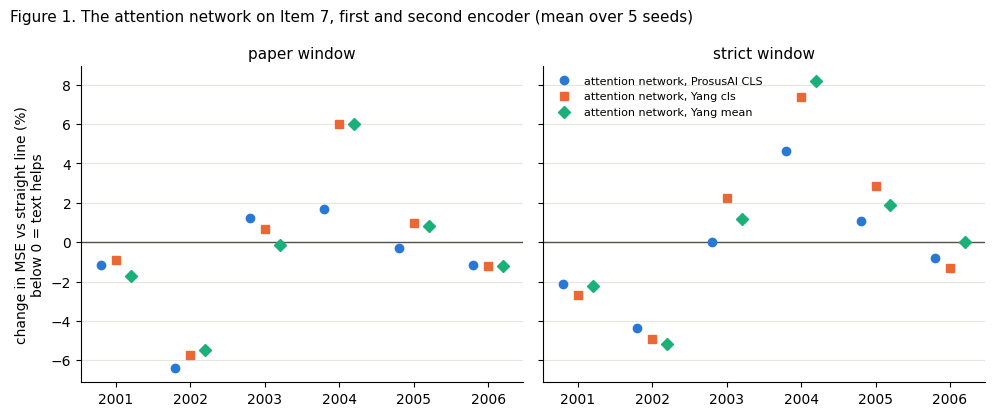

In [32]:
out = Path("../data/output")
files = [out / "alex-04-ridge-results.csv", out / "alex-04-results.csv"]
if all(f.exists() for f in files):
    new = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    old = pd.concat([pd.read_csv(out / "alex-02-ridge-results.csv"), pd.read_csv(out / "alex-03-attention-results.csv")])
    old = old[old["model"].str.startswith(("within-year ridge, Item 7", "attention pooling, Item 7"))]
    both = pd.concat([old.assign(vectors="ProsusAI CLS"), new.assign(vectors=new["model"].str.extract(r"(Yang \w+)")[0])])
    both["model_type"] = np.where(both["model"].str.startswith("within"), "within-year ridge", "attention network")
    table = (both.groupby(["model_type", "vectors", "window", "test_year"])["change_pct"].mean()
             .groupby(["model_type", "vectors", "window"])
             .agg(mean_change_pct="mean", best_year="min", worst_year="max",
                  years_better_than_line=lambda c: int((c < 0).sum())).round(2))
    display(table)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
    STYLE = {"ProsusAI CLS": ("#2a78d6", "o", -0.2), "Yang cls": ("#eb6834", "s", 0.0), "Yang mean": ("#1baf7a", "D", 0.2)}
    for ax, window in zip(axes, scoring.WINDOWS):
        ax.axhline(0, color="#52514e", lw=1)
        for v, (colour, marker, nudge) in STYLE.items():
            s = both[(both.model_type == "attention network") & (both.vectors == v) & (both.window == window)]
            s = s.groupby("test_year")["change_pct"].mean()
            ax.plot(s.index + nudge, s, marker, color=colour, ms=6, label=f"attention network, {v}")
        ax.set_title(f"{window} window", fontsize=11)
        ax.set_xticks(list(scoring.TEST_YEARS))
        ax.grid(axis="y", color="#e6e5e0", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].set_ylabel("change in MSE vs straight line (%)\nbelow 0 = text helps")
    axes[-1].legend(frameon=False, fontsize=8)
    fig.suptitle("Figure 1. The attention network on Item 7, first and second encoder (mean over 5 seeds)",
                 fontsize=11, x=0.01, ha="left")
    fig.tight_layout()
    plt.show()
else:
    print("results not there yet")

## 7. What this shows

To be written once the run is done.

## References

- Araci, D. (2019). FinBERT: Financial sentiment analysis with pre-trained language models. *arXiv:1908.10063*.
- Xia, B., Rawte, V. D., Zaki, M. J. & Gupta, A. (2022). FETILDA: An effective framework for fin-tuned embeddings for long financial text documents. *arXiv:2206.06952*.
- Yang, Y., Uy, M. C. S. & Huang, A. (2020). FinBERT: A pretrained language model for financial communications. *arXiv:2006.08097*. Model: https://huggingface.co/yiyanghkust/finbert-pretrain

Course material (Data Science Toolbox, University of Bristol, 2026):

- Lecture 09.1, Introduction to Parallelism. https://dsbristol.github.io/dst/assets/slides/09.1-ParallelAlgorithms.pdf
- Lecture 09.2, Mapping, Reducing, and Computational Graphs. https://dsbristol.github.io/dst/assets/slides/09.2-ComputationalGraphs.pdf